# Plot Matrix Factorization Results

Load saved data and recreate the original plots without rerunning the experiment.

In [1]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
from utils import plot_figures, plot_for_paper_2, plot_for_paper_penalty

In [2]:
DATA_FILE = Path("mf_results.pkl")
if not DATA_FILE.exists():
    DATA_FILE = Path("MF") / DATA_FILE
with DATA_FILE.open("rb") as result_file:
    results = pickle.load(result_file)
histories = results["histories"]
labels = results["labels"]
history_list = [histories[label] for label in labels]
print(f"Loaded {len(history_list)} histories from {DATA_FILE}")

Loaded 8 histories from mf_results.pkl


In [3]:
line_widths = [2.5] * len(labels)
line_styles = ["-"] * len(labels)
colors = ["#E8601C", "gold", "black", "#9B8AC4", "#88A5DD", "#8DCBE4", "#C2E3D2", "#DDECBF"]
marker_cycle = ["None", "*", "s", "^", "D", "x", "v", "h"]
mn_func = min(np.min(history["func"]) for history in history_list)

last func residual of Gradient Method: 0.007221487492254042
last func residual of Cubic Newton: 24785.621171335042
last func residual of LeAP-SSN: 0.00343259718352229
last func residual of GLAd-SSN, p=0.2: 7.993605777301127e-15
last func residual of GLAd-SSN, p=0.4: 0.0
last func residual of GLAd-SSN, p=0.5: 8.43769498715119e-14
last func residual of GLAd-SSN, p=0.6: 0.003409375816790572
last func residual of GLAd-SSN, p=0.8: 2.1582735598713043e-13
last func residual of Gradient Method: 2.487193920363445e-06
last func residual of Cubic Newton: 4600.231237882602
last func residual of LeAP-SSN: 1.3535459533099088e-06
last func residual of GLAd-SSN, p=0.2: 7.10361720573366e-09
last func residual of GLAd-SSN, p=0.4: 6.6831988798590346e-09
last func residual of GLAd-SSN, p=0.5: 9.009974744832012e-09
last func residual of GLAd-SSN, p=0.6: 2.0041521902969568e-08
last func residual of GLAd-SSN, p=0.8: 1.1482414178191838e-08


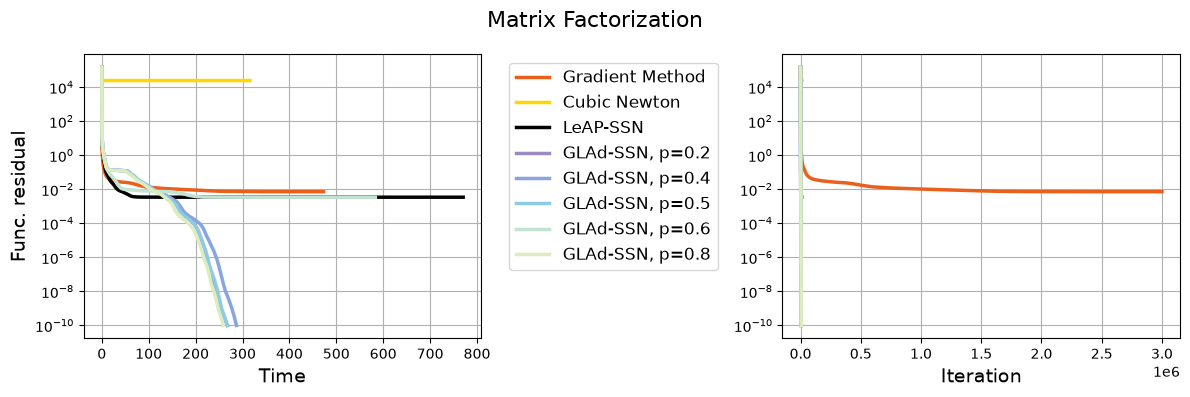

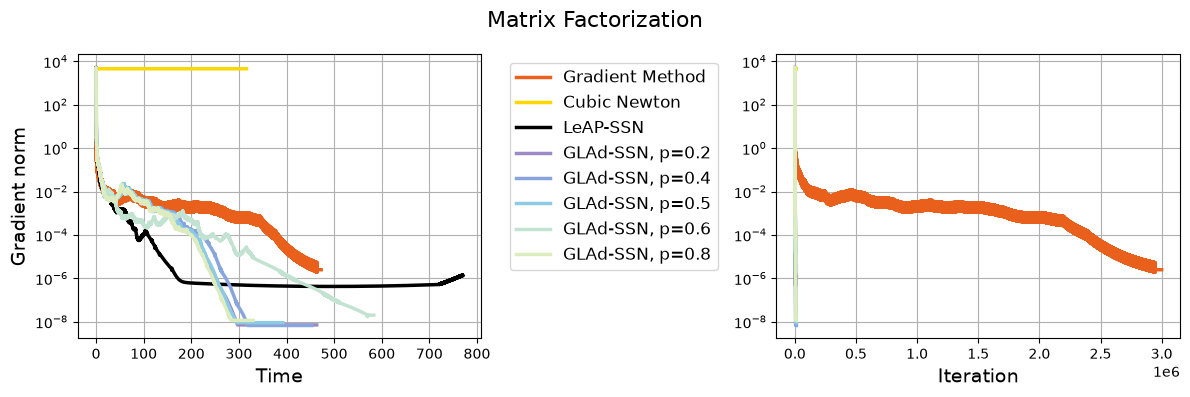

In [4]:
plot_figures(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Matrix Factorization", which_measure_2="func", max_iter=1000)
plot_figures(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=0, threshold=1e-10, suptitle="Matrix Factorization", max_iter=1000, which_measure_1="grad_norm", which_measure_2="grad_norm", ylabel="Gradient norm")

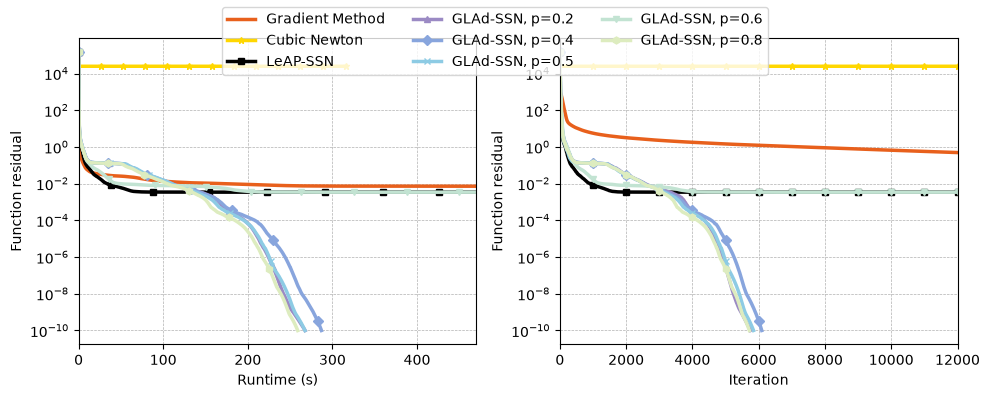

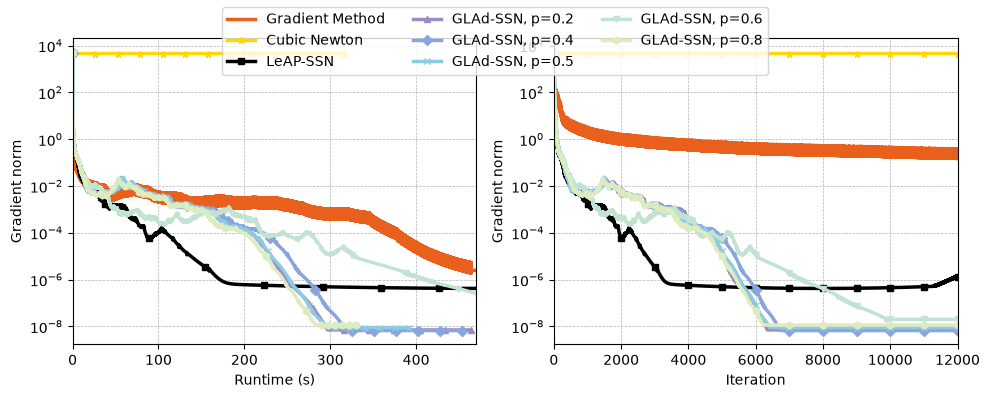

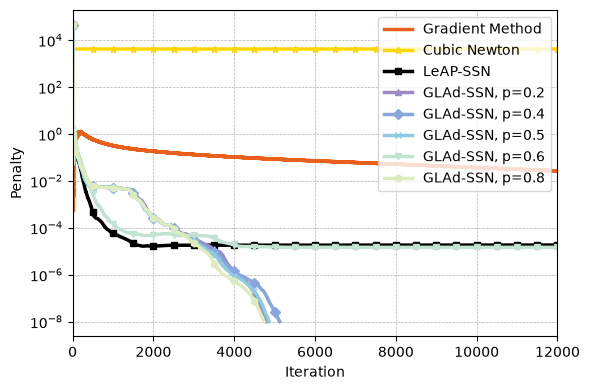

In [5]:
markevery_numbers = [50000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
plot_for_paper_2(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Plots", max_iter=12000, which_measure="func", marker_cycle=marker_cycle, markevery_numbers=markevery_numbers)
plot_for_paper_2(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Plots", max_iter=12000, which_measure="grad_norm", marker_cycle=marker_cycle, markevery_numbers=markevery_numbers)
plot_for_paper_penalty(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, marker_cycle=marker_cycle, max_time=12000)